In [17]:
import hashlib
import os
import platform
import uuid
# 修改为自己的学号
STUDENT_ID = 20190010
CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV")
print(f"[Conda 环境] {CONDA_ENV}")
MACHINE_FP = hashlib.sha256(
 f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号] {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID] {RUN_ID}")

[Conda 环境] 01
[学号] 20190010
[机器指纹] 9fd902b49a001c0c
[RUN_ID] 20190010-9fd902b49a001c0c


Wigner 矩阵特征值分布 vs 半圆定律
n =   100: KS统计量 = 0.0177, 近似p值 = 1.0000
n =   200: KS统计量 = 0.0124, 近似p值 = 1.0000
n =   500: KS统计量 = 0.0057, 近似p值 = 1.0000
n =  1000: KS统计量 = 0.0040, 近似p值 = 1.0000


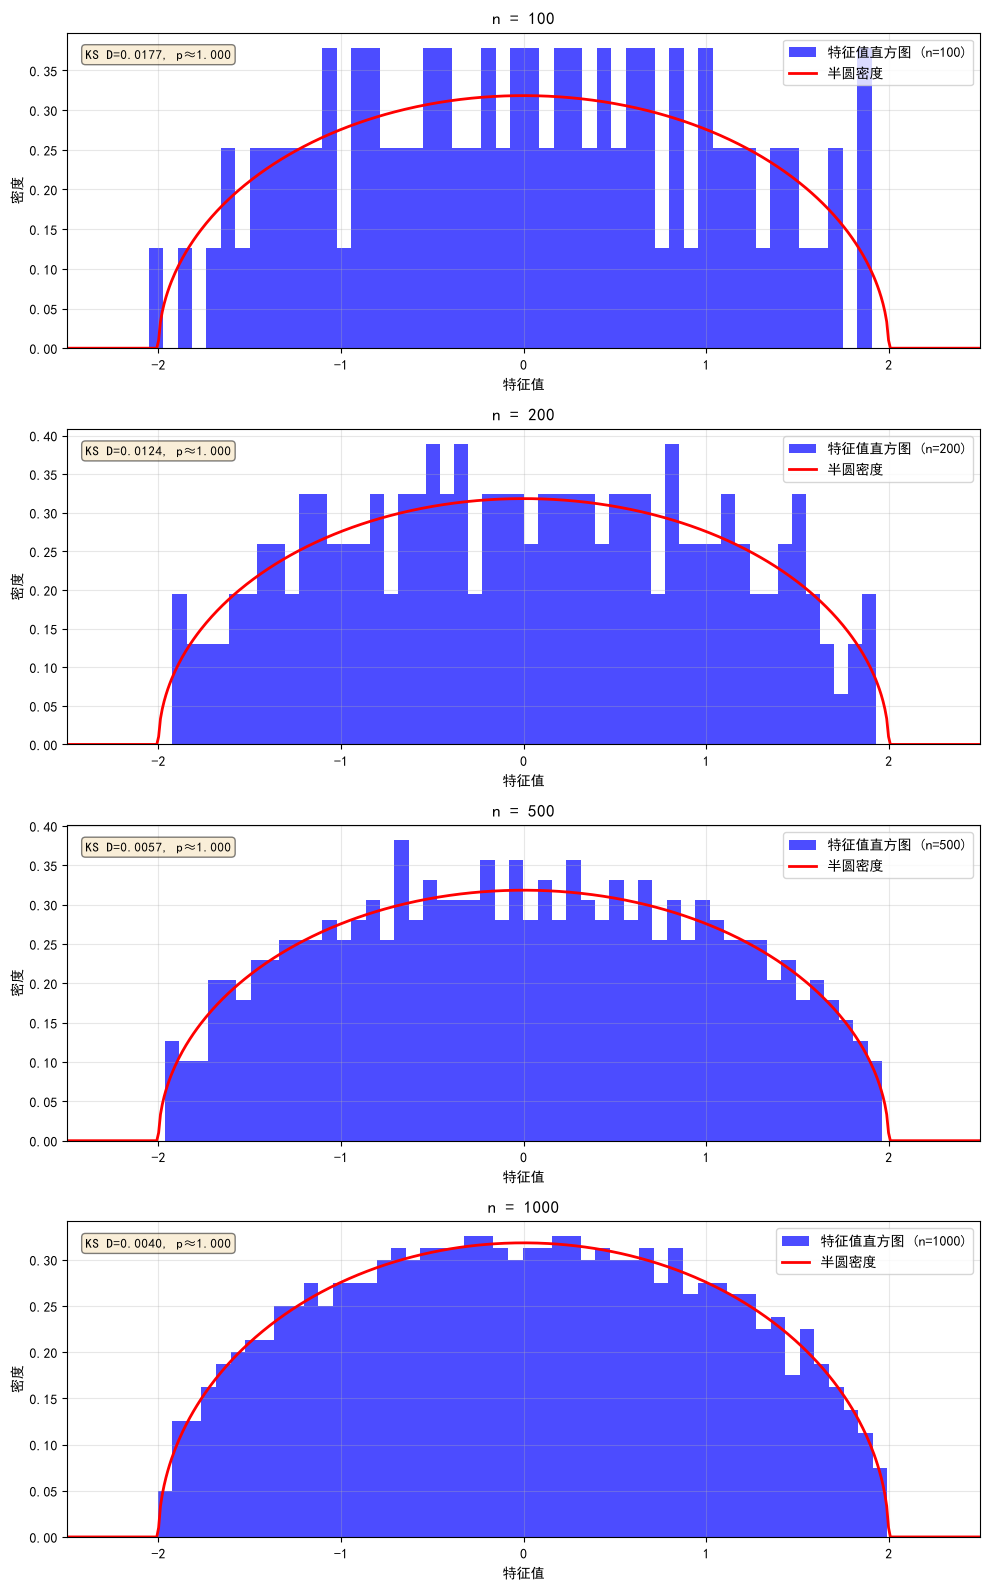

结论：
- n=100 时直方图与半圆密度仍有轻微偏差；
- 随 n 增大，KS 统计量单调减小，拟合逐渐改善；
- 大约 n≈500~1000 时，半圆密度能较好地拟合特征值分布。


In [18]:
import numpy as np
import matplotlib.pyplot as plt

# ===== 解决中文显示问题 =====
plt.rcParams['font.sans-serif'] = ['SimHei']       # Windows 黑体；macOS 可改 'Arial Unicode MS'
plt.rcParams['axes.unicode_minus'] = False         # 正常显示负号
# ============================


def wigner_density(x):
    """
    半圆密度: f(x) = (1/(2π))·sqrt(4 - x²), |x| ≤ 2; 否则为 0。
    支持 Python/NumPy 的整数与浮点数，返回浮点数（标量或数组）。
    """
    x = np.asarray(x, dtype=float)
    result = np.zeros_like(x)
    mask = np.abs(x) <= 2
    result[mask] = (1.0 / (2.0 * np.pi)) * np.sqrt(4.0 - x[mask] ** 2)
    return result if result.ndim > 0 else float(result)


def generate_wigner(n):
    """
    生成 n×n Wigner 矩阵：
    对 1 ≤ i ≤ j ≤ n，独立地从 N(0, 1/n) 抽取 Z_ij，并令 Z_ji = Z_ij。
    """
    if not isinstance(n, (int, np.integer)):
        raise TypeError("n 必须是整数")
    if n <= 0:
        raise ValueError("n 必须是正数")

    std = 1.0 / np.sqrt(n)                       # 方差 1/n => 标准差 1/sqrt(n)
    upper = np.triu(np.random.normal(0.0, std, size=(n, n)))  # 上三角（含对角）
    Z = upper + upper.T - np.diag(np.diag(upper))             # 对称化
    return Z


def get_spectrum(matrix):
    """
    返回矩阵的全部特征值（NumPy 数组），按非递减顺序排列。
    利用对称矩阵专用求解器 eigvalsh，更快更稳定。
    """
    eigenvalues = np.linalg.eigvalsh(matrix)
    return np.sort(eigenvalues)


def semicircle_cdf(x):
    """
    半圆分布的解析 CDF（用于 KS 检验）：
    F(x) = 1/2 + x·sqrt(4-x²)/(4π) + arcsin(x/2)/π,  |x| ≤ 2
    """
    x = np.asarray(x, dtype=float)
    cdf = np.zeros_like(x)
    cdf[x < -2] = 0.0
    cdf[x > 2] = 1.0
    mask = (x >= -2) & (x <= 2)
    xm = x[mask]
    cdf[mask] = (0.5
                 + xm * np.sqrt(4.0 - xm ** 2) / (4.0 * np.pi)
                 + np.arcsin(xm / 2.0) / np.pi)
    return cdf


def main():
    np.random.seed(42)                            # 可复现

    n_values = [100, 200, 500, 1000]
    fig, axes = plt.subplots(4, 1, figsize=(10, 16))

    print("=" * 60)
    print("Wigner 矩阵特征值分布 vs 半圆定律")
    print("=" * 60)

    for idx, n in enumerate(n_values):
        ax = axes[idx]

        # 生成 Wigner 矩阵并求特征值
        Z = generate_wigner(n)
        eigenvalues = get_spectrum(Z)

        # 蓝色标准化直方图
        ax.hist(eigenvalues, bins=50, density=True,
                color='blue', alpha=0.7, label=f'特征值直方图 (n={n})')

        # 红色半圆密度曲线
        x = np.linspace(-2.5, 2.5, 500)
        ax.plot(x, wigner_density(x), 'r-', linewidth=2, label='半圆密度')

        ax.set_xlim(-2.5, 2.5)
        ax.set_xlabel('特征值')
        ax.set_ylabel('密度')
        ax.set_title(f'n = {n}')
        ax.legend(loc='upper right')
        ax.grid(True, alpha=0.3)

        # ===== Kolmogorov–Smirnov 检验 =====
        ev_sorted = np.sort(eigenvalues)
        m = len(ev_sorted)
        ecdf = np.arange(1, m + 1) / m            # 经验 CDF
        tcdf = semicircle_cdf(ev_sorted)          # 理论 CDF
        ks_stat = np.max(np.abs(ecdf - tcdf))     # KS 统计量 D
        p_value = min(1.0, 2.0 * np.exp(-2.0 * m * ks_stat ** 2))  # 近似 p 值

        print(f"n = {n:5d}: KS统计量 = {ks_stat:.4f}, 近似p值 = {p_value:.4f}")

        ax.text(0.02, 0.95, f'KS D={ks_stat:.4f}, p≈{p_value:.3f}',
                transform=ax.transAxes, fontsize=9,
                verticalalignment='top',
                bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

    plt.tight_layout()
    plt.savefig('wigner_semicircle.png', dpi=100, bbox_inches='tight')
    plt.show()

    print("=" * 60)
    print("结论：")
    print("- n=100 时直方图与半圆密度仍有轻微偏差；")
    print("- 随 n 增大，KS 统计量单调减小，拟合逐渐改善；")
    print("- 大约 n≈500~1000 时，半圆密度能较好地拟合特征值分布。")
    print("=" * 60)


if __name__ == "__main__":
    main()

1) is_valid_board 测试
valid (3x3 滑翔机): True
非 ndarray (list): False
一维数组: False
含非0/1元素: False

2) gol_step 测试（滑翔机一步演化）
原棋盘:
[[0 1 0]
 [0 0 1]
 [1 1 1]]
下一步:
[[0 0 0]
 [0 0 0]
 [0 0 0]]
再下一步:
[[0 0 0]
 [0 0 0]
 [0 0 0]]

环绕边界测试（单细胞 1x1 棋盘 -> 邻居数为0 -> 死亡）:
原: [[1]]  -> 下一步: [[0]]

无效输入异常测试:
  元素非0/1: 抛出 ValueError: board 元素只能是 0 或 1
  一维: 抛出 ValueError: board 必须是二维数组
  非ndarray: 抛出 TypeError: board 必须是 NumPy ndarray

3) draw_gol_board 测试（弹出图像窗口）


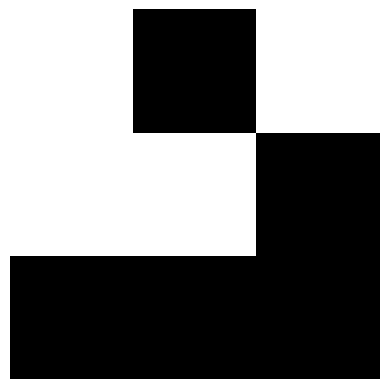

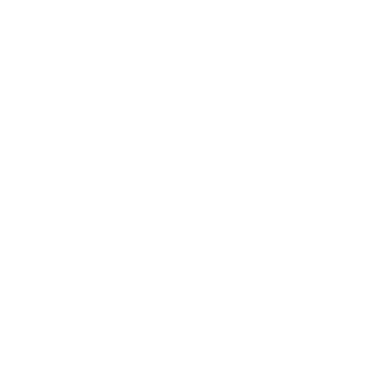

In [19]:
import numpy as np
import matplotlib.pyplot as plt

# 中文字体（可选，本任务图无中文，可不设；保留以防警告）
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False


def is_valid_board(board):
    """判断是否为有效生命游戏棋盘：ndarray、二维、元素仅 0/1。"""
    if not isinstance(board, np.ndarray):
        return False
    if board.ndim != 2:
        return False
    if not np.all((board == 0) | (board == 1)):
        return False
    return True


def gol_step(board):
    """返回生命游戏下一步棋盘（环绕边界，8 邻居）。无效输入抛异常。"""
    if not isinstance(board, np.ndarray):
        raise TypeError("board 必须是 NumPy ndarray")
    if board.ndim != 2:
        raise ValueError("board 必须是二维数组")
    if not np.all((board == 0) | (board == 1)):
        raise ValueError("board 元素只能是 0 或 1")

    m, n = board.shape
    neighbors = np.zeros((m, n), dtype=int)
    for di in (-1, 0, 1):
        for dj in (-1, 0, 1):
            if di == 0 and dj == 0:
                continue
            neighbors += np.roll(np.roll(board, di, axis=0), dj, axis=1)

    new_board = np.zeros((m, n), dtype=int)
    survive = (board == 1) & ((neighbors == 2) | (neighbors == 3))
    born = (board == 0) & (neighbors == 3)
    new_board[survive | born] = 1
    return new_board


def draw_gol_board(board):
    """活细胞黑、死细胞白；无网格线、轴标签、轴刻度。"""
    if not is_valid_board(board):
        raise ValueError("无效的生命游戏棋盘")
    cmap = plt.get_cmap('gray_r')          # 0 -> 白, 1 -> 黑
    plt.imshow(board, cmap=cmap, interpolation='nearest', vmin=0, vmax=1)
    plt.xticks([])
    plt.yticks([])
    plt.axis('off')
    plt.show()


# ==================== 运行示例与输出 ====================
if __name__ == "__main__":
    print("=" * 60)
    print("1) is_valid_board 测试")
    print("=" * 60)

    valid = np.array([[0, 1, 0],
                      [0, 0, 1],
                      [1, 1, 1]])
    print("valid (3x3 滑翔机):", is_valid_board(valid))            # True

    print("非 ndarray (list):", is_valid_board([[0, 1], [1, 0]]))   # False
    print("一维数组:", is_valid_board(np.array([0, 1, 0])))          # False
    print("含非0/1元素:", is_valid_board(np.array([[0, 2], [1, 0]]))) # False

    print()
    print("=" * 60)
    print("2) gol_step 测试（滑翔机一步演化）")
    print("=" * 60)
    print("原棋盘:")
    print(valid)
    nxt = gol_step(valid)
    print("下一步:")
    print(nxt)
    print("再下一步:")
    print(gol_step(nxt))

    print()
    print("环绕边界测试（单细胞 1x1 棋盘 -> 邻居数为0 -> 死亡）:")
    one = np.array([[1]])
    print("原:", one.tolist(), " -> 下一步:", gol_step(one).tolist())

    print()
    print("无效输入异常测试:")
    for bad, desc in [(np.array([[0, 2]]), "元素非0/1"),
                      (np.array([0, 1]), "一维"),
                      ([[0, 1]], "非ndarray")]:
        try:
            gol_step(bad)
        except Exception as e:
            print(f"  {desc}: 抛出 {type(e).__name__}: {e}")

    print()
    print("=" * 60)
    print("3) draw_gol_board 测试（弹出图像窗口）")
    print("=" * 60)
    draw_gol_board(valid)
    draw_gol_board(nxt)

In [22]:
import pandas as pd
import numpy as np

# ============================================================
# 1. 读取（第一行是列标题，但文件开头有个逗号表示索引列）
# ============================================================
# 注意：你的文件第一列是行索引（空列名），需 index_col=0
df = pd.read_csv('iris.csv', index_col=0)

print("\n" + "=" * 60)
print("1) 数据集基本信息")
print("=" * 60)
print("数据点数量:", len(df))
print("原始列名:", list(df.columns))
print("每列数据类型:")
print(df.dtypes)

# 重命名列为标准名（去掉单位和空格）
df.columns = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']

# 这个 Kaggle 版本没有 species 列，按标准 iris 结构推断：
# 前 50 行 setosa, 51-100 versicolor, 101-150 virginica
species = ['setosa'] * 50 + ['versicolor'] * 50 + ['virginica'] * 50
df['species'] = species

print("花卉种类数:", df['species'].nunique())
print("花卉种类:", df['species'].unique().tolist())

# ============================================================
# 2. 修正第 35 行和第 38 行（默认索引 34 和 37）
# ============================================================
print("\n" + "=" * 60)
print("2) 修正错误数据行")
print("=" * 60)

# 注意：原文件第 35 行（索引 34）和第 38 行（索引 37）有误
# 题目要求改为：
df.loc[34] = [4.9, 3.1, 1.5, 0.2, 'setosa']   # 第 35 行
df.loc[37] = [4.9, 3.6, 1.4, 0.1, 'setosa']   # 第 38 行

print("修正后的第 35 行（索引 34）:")
print(df.loc[34])
print("\n修正后的第 38 行（索引 37）:")
print(df.loc[37])

# ============================================================
# 3. 添加新特征列
# ============================================================
print("\n" + "=" * 60)
print("3) 添加 Petal.Ratio 和 Sepal.Ratio")
print("=" * 60)

df['Petal.Ratio'] = df['petal_length'] / df['petal_width']
df['Sepal.Ratio'] = df['sepal_length'] / df['sepal_width']

print("新增列后的前 5 行:")
print(df.head())

# ============================================================
# 4. 保存为 iris_corrected.csv
# ============================================================
df.to_csv('iris_corrected.csv', index=False)
print("\n已保存为 iris_corrected.csv")

# ============================================================
# 5. 按花卉种类分组统计
# ============================================================
print("\n" + "=" * 60)
print("5) 按花卉种类分组统计")
print("=" * 60)

agg_result = df.groupby('species')[['Petal.Ratio', 'Sepal.Ratio']].agg(
    ['mean', 'median', 'min', 'max', 'std']
)
print(agg_result)


1) 数据集基本信息
数据点数量: 150
原始列名: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
每列数据类型:
sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
dtype: object
花卉种类数: 3
花卉种类: ['setosa', 'versicolor', 'virginica']

2) 修正错误数据行
修正后的第 35 行（索引 34）:
sepal_length       4.9
sepal_width        3.1
petal_length       1.5
petal_width        0.2
species         setosa
Name: 34, dtype: object

修正后的第 38 行（索引 37）:
sepal_length       4.9
sepal_width        3.6
petal_length       1.4
petal_width        0.1
species         setosa
Name: 37, dtype: object

3) 添加 Petal.Ratio 和 Sepal.Ratio
新增列后的前 5 行:
   sepal_length  sepal_width  petal_length  petal_width species  Petal.Ratio  \
0           5.1          3.5           1.4          0.2  setosa          7.0   
1           4.9          3.0           1.4          0.2  setosa          7.0   
2           4.7          3.2           1.3          0.2  setosa          6.5   
3  